# RBI Grade A 2027: One Practical Python Project Per Day

**Plan:** learn the exam's ideas by *building* them. Every day = one small project you run, break, and extend.
Python skill and exam understanding grow together, and the projects double as a freelance portfolio.

<div style="background:#e3f2fd;border-left:6px solid #1565c0;padding:8px 12px;margin:6px 0;color:#111"><b>How to use this notebook</b><br>1. Read the coloured boxes (5 minutes). 2. Run the code cell. 3. Do the 'Your turn' tasks (the real learning). 4. Tick the day in the tracker at the bottom. Target: 60 to 90 minutes a day, one rest or mock-test day each week.</div><div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>About the book</b><br><i>Python: The Complete Reference</i> (Martin C. Brown) was written in the Python 2 era. Use it for the <b>concepts</b> (variables, loops, functions, strings, lists, dictionaries, files, exceptions, classes, modules), but write code in <b>Python 3</b>: <code>print(x)</code> not <code>print x</code>, <code>input()</code> not <code>raw_input()</code>, and <code>/</code> always gives a decimal. For exact syntax, check docs.python.org/3.</div><div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>Be honest about the exam</b><br>Python will not replace studying the syllabus (Economic and Social Issues, Finance and Management, English descriptive writing, aptitude). It is your <b>lab</b>: you test every formula and concept in code so it sticks without rote learning. Confirm dates, pattern and marking on the official RBI notification at rbi.org.in. All numbers below are practice values, not official data.</div>

In [1]:
# Shared helpers used across days. Run this cell first, every session.
import math, random, json, csv, re, tempfile, os
from collections import Counter
from dataclasses import dataclass

def inr(x):
    # Format a number the Indian way: 2000000 -> Rs 20,00,000
    x = round(x)
    s = str(abs(x))
    if len(s) > 3:
        head, tail = s[:-3], s[-3:]
        parts = []
        while len(head) > 2:
            parts.insert(0, head[-2:]); head = head[:-2]
        if head: parts.insert(0, head)
        s = ",".join(parts + [tail])
    return ("-" if x < 0 else "") + "\u20b9" + s

print(inr(2000000), inr(1234567), inr(950))

₹20,00,000 ₹12,34,567 ₹950


## Day 1: Loan and Interest Calculator (SI, CI, EMI)

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>Quant aptitude (interest), Finance paper (time value of money, bank lending).</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>Variables, operators, functions, return values, f-strings.</div>
<div style="background:#e3f2fd;border-left:6px solid #1565c0;padding:8px 12px;margin:6px 0;color:#111"><b>Real-life picture</b><br>Think of the udhaar in a kirana shop where the shopkeeper adds interest on last month's interest too. That is compounding.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Every neural-network layer is just a function. Writing clean input-to-output functions today is the same habit.</div>

In [2]:
def simple_interest(p, r, t):
    return p * r * t / 100

def compound_interest(p, r, t, n=1):
    # n = compounding periods per year
    amount = p * (1 + r / (100 * n)) ** (n * t)
    return amount - p

def emi(p, annual_rate, months):
    r = annual_rate / 12 / 100
    return p * r * (1 + r) ** months / ((1 + r) ** months - 1)

# Self-checks: if one fails, your understanding (or code) is wrong. That is the point.
assert simple_interest(1000, 10, 2) == 200
assert round(compound_interest(1000, 10, 2), 2) == 210.00

loan = 20_00_000
print("Home loan:", inr(loan), "at 8.5% for 20 years")
monthly = emi(loan, 8.5, 240)
print("EMI per month:", inr(monthly))
print("Total paid   :", inr(monthly * 240))
print("Total interest:", inr(monthly * 240 - loan))

Home loan: ₹20,00,000 at 8.5% for 20 years
EMI per month: ₹17,356
Total paid   : ₹41,65,552
Total interest: ₹21,65,552


<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Compare SI and CI on 1,00,000 at 8% for 5 years. Why does the gap widen with time? 2) Try EMI for 10, 15, 20 years. Write one sentence on what changes. 3) Add a function that gives the effective annual rate for quarterly compounding.</div>

## Day 2: Quant Toolkit: Percent, Profit, Ratio, Work, CAGR

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>Quantitative aptitude in Phase 1 (speed + accuracy).</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>Functions with default arguments, dictionaries as a menu of tools, assert statements for testing.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Dictionaries of functions are how real ML code picks a loss function or optimizer by name.</div>

In [3]:
def profit_pct(cp, sp): return (sp - cp) / cp * 100
def successive_change(*pcts):
    v = 100
    for p in pcts: v *= (1 + p / 100)
    return v - 100
def split_ratio(total, *ratio):
    s = sum(ratio); return [total * x / s for x in ratio]
def work_together(*days): return 1 / sum(1 / d for d in days)
def cagr(start, end, years): return ((end / start) ** (1 / years) - 1) * 100

TOOLS = {"profit%": profit_pct, "successive%": successive_change,
         "ratio": split_ratio, "work": work_together, "cagr": cagr}

assert round(profit_pct(80, 100), 2) == 25.0
assert round(successive_change(20, -10), 2) == 8.0        # not 10! Percent changes do not add.
assert split_ratio(900, 2, 3, 4) == [200.0, 300.0, 400.0]
assert round(work_together(12, 6), 2) == 4.0
print("All checks passed")
print("A grows 100 -> 180 in 4 years, CAGR =", round(TOOLS["cagr"](100, 180, 4), 2), "%")
print("Price +20% then -10% nets", successive_change(20, -10), "%")

All checks passed
A grows 100 -> 180 in 4 years, CAGR = 15.83 %
Price +20% then -10% nets 8.0 %


<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Add a function for 'A and B work together, B leaves after x days'. 2) Time yourself solving 10 questions by hand, then verify each with your toolkit. 3) Save every question you got wrong into a list (you will use this idea on Day 10).</div>

## Day 3: Money Multiplier and CRR Simulator

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>Economic and Social Issues + Finance: CRR, credit creation, monetary policy transmission.</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>for and while loops, tuples, list of rows, formatted tables.</div>
<div style="background:#e3f2fd;border-left:6px solid #1565c0;padding:8px 12px;margin:6px 0;color:#111"><b>Real-life picture</b><br>A chit-fund organiser keeps part of the pool aside and lends the rest; the borrower pays a vendor who deposits it again. The pool keeps circling.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Loops that update a value each round are the same pattern as gradient descent updating weights each step.</div>

In [4]:
def deposit_expansion(initial, crr, rounds=12):
    rows, deposit, total = [], initial, 0
    for i in range(1, rounds + 1):
        keep = deposit * crr          # bank parks this with RBI as CRR
        lend = deposit - keep         # the rest is lent, and comes back as a new deposit
        total += deposit
        rows.append((i, deposit, keep, lend))
        deposit = lend
    return rows, total

crr = 0.04                             # practice value; check the current CRR on rbi.org.in
rows, total = deposit_expansion(1_00_000, crr)
print(f"{'Round':<6}{'Deposit':>14}{'Kept (CRR)':>14}{'Lent out':>14}")
for i, d, k, l in rows:
    print(f"{i:<6}{inr(d):>14}{inr(k):>14}{inr(l):>14}")
print("\nTotal deposits after 12 rounds:", inr(total))
print("Theory (initial / CRR)        :", inr(1_00_000 / crr), "  <- the limit as rounds go to infinity")

Round        Deposit    Kept (CRR)      Lent out
1          ₹1,00,000        ₹4,000       ₹96,000
2            ₹96,000        ₹3,840       ₹92,160
3            ₹92,160        ₹3,686       ₹88,474
4            ₹88,474        ₹3,539       ₹84,935
5            ₹84,935        ₹3,397       ₹81,537
6            ₹81,537        ₹3,261       ₹78,276
7            ₹78,276        ₹3,131       ₹75,145
8            ₹75,145        ₹3,006       ₹72,139
9            ₹72,139        ₹2,886       ₹69,253
10           ₹69,253        ₹2,770       ₹66,483
11           ₹66,483        ₹2,659       ₹63,824
12           ₹63,824        ₹2,553       ₹61,271

Total deposits after 12 rounds: ₹9,68,226
Theory (initial / CRR)        : ₹25,00,000   <- the limit as rounds go to infinity


<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Run with CRR 3%, 4%, 6%. What happens to total credit when RBI raises CRR? Link it to inflation control. 2) Add a 'cash leakage' rate (people keep some cash at home) and see the multiplier shrink. 3) Write 3 lines in your own words: why does RBI change CRR instead of printing less money directly?</div>

## Day 4: CPI Basket and Inflation Calculator

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>ESI paper: CPI, WPI, inflation targeting, real vs nominal returns.</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>Nested dictionaries, sum() with generators, rounding, simple reports.</div>
<div style="background:#e3f2fd;border-left:6px solid #1565c0;padding:8px 12px;margin:6px 0;color:#111"><b>Real-life picture</b><br>A household monthly budget: if 46 rupees of every 100 go to food, a vegetable price spike hits you far more than a change in clothing prices.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Weighted sums are exactly what a neuron does: weights times inputs, added up.</div>

In [5]:
# Illustrative weights (sum = 100). Real CPI weights are published by MoSPI.
basket = {
    "Food & beverages": {"w": 46, "base": 100, "now": 108},
    "Housing":          {"w": 10, "base": 100, "now": 104},
    "Fuel & light":     {"w": 7,  "base": 100, "now": 103},
    "Clothing":         {"w": 6,  "base": 100, "now": 105},
    "Transport & edu":  {"w": 16, "base": 100, "now": 106},
    "Health & other":   {"w": 15, "base": 100, "now": 107},
}
assert sum(v["w"] for v in basket.values()) == 100

index_now = sum(v["w"] * v["now"] for v in basket.values()) / 100
inflation = index_now - 100            # base index is 100
print("CPI index now:", round(index_now, 2), "| inflation vs base:", round(inflation, 2), "%")

for name, v in sorted(basket.items(), key=lambda kv: kv[1]["w"] * (kv[1]["now"] - 100), reverse=True):
    contrib = v["w"] * (v["now"] - 100) / 100
    print(f"{name:<20} contributes {contrib:5.2f} points")

def real_return(nominal, infl): return ((1 + nominal / 100) / (1 + infl / 100) - 1) * 100
print("\nFD gives 7% while inflation is", round(inflation, 1), "% -> real return:",
      round(real_return(7, inflation), 2), "%")

CPI index now: 106.6 | inflation vs base: 6.6 %
Food & beverages     contributes  3.68 points
Health & other       contributes  1.05 points
Transport & edu      contributes  0.96 points
Housing              contributes  0.40 points
Clothing             contributes  0.30 points
Fuel & light         contributes  0.21 points

FD gives 7% while inflation is 6.6 % -> real return: 0.38 %


<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Make food prices jump 20% and see how headline inflation reacts. Why does a high food weight make Indian CPI volatile? 2) Check the RBI inflation target band and write it in a comment. 3) Compute the real return of a 6.5% savings product at 4%, 6%, 8% inflation.</div>

## Day 5: Macro Data Pipeline with CSV Files

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>ESI paper: GDP growth, trends, reading statistical tables (RBI Handbook of Statistics style).</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>File handling (open, with), the csv module, type conversion, max/min with key.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Every ML project starts with loading and cleaning data like this. Real work is 70% data handling.</div>

In [6]:
path = os.path.join(tempfile.gettempdir(), "growth_practice.csv")
practice = [("Year-1", 7.2), ("Year-2", 6.8), ("Year-3", 8.0), ("Year-4", -5.8),
            ("Year-5", 9.1), ("Year-6", 7.0), ("Year-7", 8.2)]   # made-up practice numbers

with open(path, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["year", "growth_pct"])
    w.writerows(practice)

with open(path) as f:
    data = [(r["year"], float(r["growth_pct"])) for r in csv.DictReader(f)]

growths = [g for _, g in data]
print("Average growth:", round(sum(growths) / len(growths), 2), "%")
print("Best year :", max(data, key=lambda x: x[1]))
print("Worst year:", min(data, key=lambda x: x[1]))

level = 100
for _, g in data: level *= 1 + g / 100
print("GDP index after all years:", round(level, 1), "| CAGR:",
      round(((level / 100) ** (1 / len(data)) - 1) * 100, 2), "%")
print("Simple average (", round(sum(growths)/len(growths),2), ") vs CAGR differ because growth compounds.")

Average growth: 5.79 %
Best year : ('Year-5', 9.1)
Worst year: ('Year-4', -5.8)
GDP index after all years: 147.1 | CAGR: 5.67 %
Simple average ( 5.79 ) vs CAGR differ because growth compounds.


<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Replace the practice numbers with real figures you type from an official RBI or MoSPI table. 2) Add a function that flags years with negative growth. 3) Wrap file reading in try/except for a missing file (preview of Day 10).</div>

## Day 6: Text Analyzer for English Descriptive and Precis

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>English descriptive paper: precis, essay length control, vocabulary range.</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>Strings, regular expressions, sets, Counter, slicing.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Counting words and tokens is step one of every NLP pipeline, including the RAG systems you have already built.</div>

In [7]:
text = ("Monetary policy aims to keep inflation stable while supporting growth. "
        "When prices rise too fast, the central bank can raise the policy rate, which makes borrowing costlier. "
        "Costlier loans reduce spending, and lower spending eases price pressure. "
        "However, the effect is not instant, and policy works with a lag. "
        "Therefore, communication about future intent is itself a policy tool.")

STOP = set("the a an and or of to in is it its that which can when while with for not are be by as this".split())
sentences = [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]
words = re.findall(r"[A-Za-z']+", text.lower())
content = [w for w in words if w not in STOP]

print("Sentences:", len(sentences), "| Words:", len(words),
      "| Avg words/sentence:", round(len(words) / len(sentences), 1))
print("Top content words:", Counter(content).most_common(5))
print("Precis target (about one third):", round(len(words) / 3), "words")
print("Longest sentence:", max(sentences, key=lambda s: len(s.split())))

Sentences: 5 | Words: 59 | Avg words/sentence: 11.8
Top content words: [('policy', 4), ('costlier', 2), ('spending', 2), ('monetary', 1), ('aims', 1)]
Precis target (about one third): 20 words
Longest sentence: When prices rise too fast, the central bank can raise the policy rate, which makes borrowing costlier.


<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Paste a 300-word editorial and run it. Write your precis, then count its words with code. 2) Add a check that flags sentences over 25 words. 3) Count how many unique words you used in last week's practice essay; aim to grow that number.</div>

## Day 7: Seating Arrangement Solver

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>Reasoning in Phase 1. Puzzles are slow by hand but exact for a computer.</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>Imports, itertools.permutations, list comprehensions, functions that return True/False.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Brute-force search over possibilities with constraints is the base idea behind search and planning in AI.</div>

In [8]:
from itertools import permutations

people = "ABCDE"

def valid(row):
    pos = {p: i for i, p in enumerate(row)}
    return (pos["A"] not in (0, 4)                 # A is not at either end
            and pos["C"] == pos["B"] + 1           # B sits immediately left of C
            and abs(pos["D"] - pos["E"]) != 1      # D and E are not neighbours
            and pos["E"] > pos["A"])               # E is to the right of A

solutions = [row for row in permutations(people) if valid(row)]
print("Number of valid arrangements:", len(solutions))
for s in solutions: print(" ".join(s))

Number of valid arrangements: 4
B C D A E
D A B C E
D A E B C
D B C A E


<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Change one condition and predict how many solutions remain before running. 2) Solve a seating puzzle from your reasoning book by encoding it here, then compare with your by-hand answer. 3) Extend to a circular table (hint: fix one person's seat).</div>

## Day 8: Number Series Detector and Syllogism Checker

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>Reasoning and aptitude: number series, syllogisms.</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>Lists, zip, sets, tuples, itertools.product, writing small test cases.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Pattern detection from examples is the heart of machine learning; the syllogism checker is a tiny logic engine.</div>

In [9]:
from fractions import Fraction
from itertools import product

def next_term(seq):
    d = [b - a for a, b in zip(seq, seq[1:])]
    if len(set(d)) == 1:
        return seq[-1] + d[0], "arithmetic"
    if all(x != 0 for x in seq):
        r = [Fraction(b, a) for a, b in zip(seq, seq[1:])]
        if len(set(r)) == 1:
            return int(seq[-1] * r[0]), "geometric"
    d2 = [b - a for a, b in zip(d, d[1:])]
    if len(set(d2)) == 1:
        return seq[-1] + d[-1] + d2[0], "second-order (gaps change evenly)"
    return None, "pattern not found"

for s in ([2, 4, 6, 8], [3, 6, 12, 24], [1, 4, 9, 16], [2, 5, 10, 17, 26]):
    print(s, "->", next_term(s))

# ---- Syllogism checker: try every possible world and see if the conclusion is always true
REGIONS = list(product([False, True], repeat=3))     # membership in (A, B, C)
IDX = {"A": 0, "B": 1, "C": 2}

def holds(stmt, world):
    kind, x, y = stmt; i, j = IDX[x], IDX[y]
    if kind == "all":      return all((not r[i]) or r[j] for r in world)
    if kind == "no":       return all(not (r[i] and r[j]) for r in world)
    if kind == "some":     return any(r[i] and r[j] for r in world)
    if kind == "some_not": return any(r[i] and not r[j] for r in world)

def worlds():
    for mask in range(1 << 8):
        yield [REGIONS[k] for k in range(8) if mask >> k & 1]

def follows(premises, conclusion):
    return all(holds(conclusion, w) for w in worlds() if all(holds(p, w) for p in premises))

# A = cats, B = animals, C = pets
print("\nAll cats are animals; all animals are pets => all cats are pets:",
      follows([("all", "A", "B"), ("all", "B", "C")], ("all", "A", "C")))
print("All cats are animals; some animals are pets => some cats are pets:",
      follows([("all", "A", "B"), ("some", "B", "C")], ("some", "A", "C")))

[2, 4, 6, 8] -> (10, 'arithmetic')
[3, 6, 12, 24] -> (48, 'geometric')
[1, 4, 9, 16] -> (25, 'second-order (gaps change evenly)')
[2, 5, 10, 17, 26] -> (37, 'second-order (gaps change evenly)')

All cats are animals; all animals are pets => all cats are pets: True
All cats are animals; some animals are pets => some cats are pets: False


<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Add a 'square plus 1' series detector. 2) Test 'Some A are B; No B is C => Some A are not C' (write your guess first). 3) Compare the code's verdicts with the Venn-diagram method you use in exams.</div>

## Day 9: Mock Test Engine with Negative Marking

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>Phase 1 strategy: attempts, accuracy, negative marking, section-wise cutoffs.</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>Classes, dataclasses, methods, dictionaries of results, defaultdict-style grouping.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Accuracy, attempt rate and per-class scores are the same metrics used to evaluate a model.</div>

In [10]:
@dataclass
class Q:
    section: str
    text: str
    options: list
    answer: int          # index of the correct option
    topic: str

class MockTest:
    def __init__(self, questions, negative=0.25):   # confirm marking scheme in the official notification
        self.qs, self.neg = questions, negative

    def score(self, responses):
        # responses: {question_index: chosen_option_index}; missing = skipped
        report = {}
        for i, q in enumerate(self.qs):
            sec = report.setdefault(q.section, {"correct": 0, "wrong": 0, "skipped": 0, "marks": 0.0})
            if i not in responses:
                sec["skipped"] += 1
            elif responses[i] == q.answer:
                sec["correct"] += 1; sec["marks"] += 1
            else:
                sec["wrong"] += 1; sec["marks"] -= self.neg
        return report

bank = [
    Q("Quant", "20% of 250 = ?", ["40", "50", "60", "25"], 1, "percentage"),
    Q("Quant", "SI on 1000 at 10% for 2 years?", ["100", "200", "210", "20"], 1, "interest"),
    Q("Reasoning", "Next in 2, 4, 8, 16?", ["24", "30", "32", "34"], 2, "series"),
    Q("GA", "RBI was established in the year?", ["1935", "1947", "1949", "1969"], 0, "banking history"),
    Q("GA", "CRR is kept with which institution?", ["SEBI", "RBI", "NABARD", "IRDAI"], 1, "monetary policy"),
    Q("English", "Synonym of 'prudent'?", ["careless", "wise", "angry", "slow"], 1, "vocabulary"),
]
test = MockTest(bank)
my_answers = {0: 1, 1: 0, 2: 2, 3: 0, 5: 1}      # I skipped question 4, got question 1 wrong
rep = test.score(my_answers)
total = 0
for sec, r in rep.items():
    total += r["marks"]
    print(f"{sec:<10} correct={r['correct']} wrong={r['wrong']} skipped={r['skipped']} marks={r['marks']}")
print("Total marks:", total)

Quant      correct=1 wrong=1 skipped=0 marks=0.75
Reasoning  correct=1 wrong=0 skipped=0 marks=1.0
GA         correct=1 wrong=0 skipped=1 marks=1.0
English    correct=1 wrong=0 skipped=0 marks=1.0
Total marks: 3.75


<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Replace the bank with 20 real questions from your practice books. 2) Add an accuracy % and attempt % per section. 3) Add a rule: print 'guess or skip?' using expected value (probability of being right times 1, minus wrong probability times the penalty).</div>

## Day 10: Mistake Notebook with JSON and Error Handling

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>All papers: your wrong answers are the most valuable study material you own.</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>Exceptions (try/except/raise), json module, list of dicts, Counter.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Error analysis, looking at exactly where a model fails, is how every ML engineer improves a model.</div>

In [11]:
log_path = os.path.join(tempfile.gettempdir(), "mistakes.json")

def load():
    try:
        with open(log_path) as f: return json.load(f)
    except FileNotFoundError:
        return []

def log_mistake(topic, reason):
    if reason not in ("concept", "calculation", "silly", "time"):
        raise ValueError("reason must be: concept / calculation / silly / time")
    data = load()
    data.append({"topic": topic, "reason": reason})
    with open(log_path, "w") as f: json.dump(data, f, indent=2)

if os.path.exists(log_path): os.remove(log_path)       # fresh demo run
for t, r in [("interest", "calculation"), ("CRR", "concept"), ("series", "silly"),
             ("CRR", "concept"), ("inflation", "concept"), ("interest", "time")]:
    log_mistake(t, r)

try:
    log_mistake("repo rate", "lazy")
except ValueError as e:
    print("Rejected bad input ->", e)

data = load()
print("Weakest topics:", Counter(d["topic"] for d in data).most_common(3))
print("Why you lose marks:", Counter(d["reason"] for d in data).most_common())

Rejected bad input -> reason must be: concept / calculation / silly / time
Weakest topics: [('interest', 2), ('CRR', 2), ('series', 1)]
Why you lose marks: [('concept', 3), ('calculation', 1), ('silly', 1), ('time', 1)]


<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Log every wrong answer from today's practice. 2) Add a function that prints a 3-topic revision plan for tomorrow from your top mistakes. 3) Notice: if 'concept' dominates, study more; if 'silly' or 'time' dominates, practise speed.</div>

## Day 11: Spaced-Repetition Flashcards (Leitner Boxes)

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>General Awareness and Finance facts you must retain for 10 months without cramming.</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>Dictionaries, random, loops over days, simulation.</div>
<div style="background:#e3f2fd;border-left:6px solid #1565c0;padding:8px 12px;margin:6px 0;color:#111"><b>Real-life picture</b><br>Like revising a tough topic the day after, then after three days, then after a week, rather than reading it ten times in one night.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Simulating a learner is a first step to reinforcement-learning thinking: state, action, reward.</div>

In [12]:
random.seed(7)
cards = {
    "RBI established": ("1 April 1935", 1),
    "RBI Act": ("1934", 1),
    "Banking Regulation Act": ("1949", 1),
    "RBI nationalised": ("1 January 1949", 1),
    "MSF rate vs repo": ("above repo (ceiling of the corridor)", 1),
}
state = {k: {"box": 1, "due": 0} for k in cards}
INTERVAL = {1: 1, 2: 3, 3: 7}          # days until next review per box

for day_no in range(0, 15):
    due_today = [k for k, s in state.items() if s["due"] <= day_no]
    for k in due_today:
        knew = random.random() < 0.6            # in real use: ask yourself and press y/n
        s = state[k]
        s["box"] = min(3, s["box"] + 1) if knew else 1
        s["due"] = day_no + INTERVAL[s["box"]]
    if due_today:
        print(f"Day {day_no:2}: reviewed {len(due_today)} cards ->",
              {k: state[k]["box"] for k in state})

Day  0: reviewed 5 cards -> {'RBI established': 2, 'RBI Act': 2, 'Banking Regulation Act': 1, 'RBI nationalised': 2, 'MSF rate vs repo': 2}
Day  1: reviewed 1 cards -> {'RBI established': 2, 'RBI Act': 2, 'Banking Regulation Act': 2, 'RBI nationalised': 2, 'MSF rate vs repo': 2}
Day  3: reviewed 4 cards -> {'RBI established': 3, 'RBI Act': 3, 'Banking Regulation Act': 2, 'RBI nationalised': 3, 'MSF rate vs repo': 3}
Day  4: reviewed 1 cards -> {'RBI established': 3, 'RBI Act': 3, 'Banking Regulation Act': 3, 'RBI nationalised': 3, 'MSF rate vs repo': 3}
Day 10: reviewed 4 cards -> {'RBI established': 3, 'RBI Act': 3, 'Banking Regulation Act': 3, 'RBI nationalised': 1, 'MSF rate vs repo': 3}
Day 11: reviewed 2 cards -> {'RBI established': 3, 'RBI Act': 3, 'Banking Regulation Act': 3, 'RBI nationalised': 1, 'MSF rate vs repo': 3}
Day 12: reviewed 1 cards -> {'RBI established': 3, 'RBI Act': 3, 'Banking Regulation Act': 3, 'RBI nationalised': 1, 'MSF rate vs repo': 3}
Day 13: reviewed 1 c

<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Replace the simulation with real input() so you quiz yourself. 2) Store cards in a JSON file and load them every morning. 3) Add 20 cards from today's newspaper reading.</div>

## Day 12: EMI Amortization Schedule and Prepayment Effect

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>RBI link</b><br>Finance paper: loans, interest, time value of money; also useful in interviews.</div>
<div style="background:#fff8e1;border-left:6px solid #f9a825;padding:8px 12px;margin:6px 0;color:#111"><b>Python concept (look it up in the book)</b><br>While loops, lists of tuples, optional plotting with matplotlib, reusing Day 1 functions.</div>
<div style="background:#f3e5f5;border-left:6px solid #7b1fa2;padding:8px 12px;margin:6px 0;color:#111"><b>Deep learning connection</b><br>Plotting a loss curve is the first thing you do in deep learning; practise plotting here.</div>

Normal   : 240 months, interest paid ₹21,65,552
+5,000/mo: 143 months, interest paid ₹11,80,774
Interest saved: ₹9,84,778 | Time saved: 97 months
First EMI split -> interest ₹14,167 | principal ₹3,190


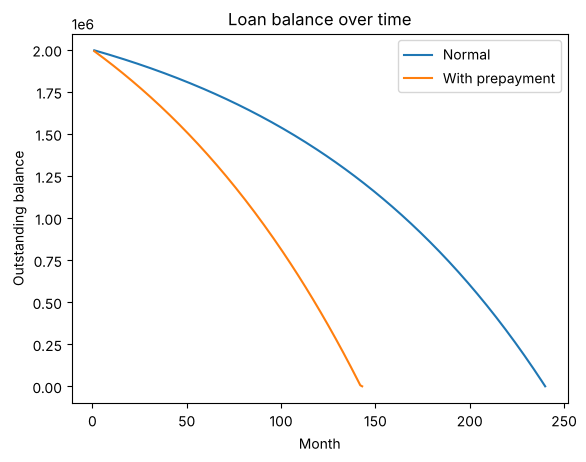

In [13]:
def emi(p, annual_rate, months):
    r = annual_rate / 1200
    return p * r * (1 + r) ** months / ((1 + r) ** months - 1)

def amortize(p, annual_rate, months, extra=0):
    r, pay = annual_rate / 1200, emi(p, annual_rate, months)
    bal, rows, m, total_int = p, [], 0, 0
    while bal > 0.005 and m < months * 2:
        m += 1
        interest = bal * r
        principal = min(pay + extra - interest, bal)
        bal -= principal; total_int += interest
        rows.append((m, interest, principal, bal))
    return rows, total_int, pay

p, rate, n = 20_00_000, 8.5, 240
base_rows, base_int, pay = amortize(p, rate, n)
pre_rows, pre_int, _ = amortize(p, rate, n, extra=5000)
print("Normal   :", len(base_rows), "months, interest paid", inr(base_int))
print("+5,000/mo:", len(pre_rows), "months, interest paid", inr(pre_int))
print("Interest saved:", inr(base_int - pre_int), "| Time saved:", len(base_rows) - len(pre_rows), "months")
print("First EMI split -> interest", inr(base_rows[0][1]), "| principal", inr(base_rows[0][2]))

try:
    import matplotlib.pyplot as plt
    plt.plot([r[0] for r in base_rows], [r[3] for r in base_rows], label="Normal")
    plt.plot([r[0] for r in pre_rows], [r[3] for r in pre_rows], label="With prepayment")
    plt.xlabel("Month"); plt.ylabel("Outstanding balance"); plt.legend(); plt.title("Loan balance over time")
    plt.show()
except ImportError:
    print("Install matplotlib to see the chart: pip install matplotlib")

<div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Your turn (do these before moving on)</b><br>1) Why is almost all of the early EMI interest, and how does that change later? Explain in two lines. 2) Try a different rate (floating loan linked to the repo rate): what happens to total cost if the rate goes up 0.5%? 3) Add a yearly summary table.</div>

## Progress Tracker

Edit the set below as you finish each day, then run the cell.

In [14]:
done = {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12}      # <- change as you go
TOTAL_DAYS = 300                                     # about Nov 2026 to Sept 2027
pct = len(done) / TOTAL_DAYS
print(f"[{'#' * int(pct * 40):<40}] {len(done)}/{TOTAL_DAYS} days ({pct:.0%})")

[#                                       ] 12/300 days (4%)


<div style="background:#e3f2fd;border-left:6px solid #1565c0;padding:8px 12px;margin:6px 0;color:#111"><b>The road ahead: Day 13 to exam</b><br>Phases are a guide. Keep one day per week for a full timed mock and one for revision.</div>

### Phase A (Nov to Dec 2026): Python basics through exam tools
| Days | Project idea | Exam link |
|---|---|---|
| 13-17 | Percentage, average, mixture and age-problem solvers | Quant |
| 18-22 | Data interpretation: read a table, draw bar and line charts | DI |
| 23-27 | Bank ratio dashboard (NPA %, CAR, credit-deposit ratio) from sample data | Finance |
| 28-32 | Repo, reverse repo, SDF, MSF corridor visualiser | ESI / Finance |
| 33-38 | Vocabulary trainer plus essay timer | English |
| 39-45 | Mini mock test app with section timers (using classes) | Phase 1 |

### Phase B (Jan to Mar 2027): data skills with real tables
| Weeks | Project idea | Exam link |
|---|---|---|
| 1-3 | Pandas and NumPy on RBI/MoSPI tables: GDP, CPI, forex reserves, BoP | ESI |
| 4-6 | Inflation vs repo rate analysis and correlation (careful: correlation is not causation) | ESI |
| 7-9 | Bond price and yield calculator; duration basics | Finance |
| 10-12 | Budget and fiscal deficit explorer; Lorenz curve and Gini | ESI |

### Phase C (Apr to Jun 2027): bring in machine learning
| Weeks | Project idea | Exam link |
|---|---|---|
| 1-3 | Linear regression from scratch on macro data (then compare with scikit-learn) | ESI + DL |
| 4-6 | Text classifier for news headlines: inflation, banking, trade, policy | GA / DL |
| 7-10 | **RAG study assistant over RBI policy statements and Master Directions** (reuse your HAL and Modi-RAG experience) | All papers |
| 11-12 | Anomaly detection on bank transactions (fraud basics) | Finance + DL |

### Phase D (Jul to Sep 2027): exam mode
| Weeks | Activity |
|---|---|
| 1-4 | Daily timed section tests logged in your mistake notebook; fix top 3 weak topics each week |
| 5-8 | Full-length mocks twice a week; analyse with your Day 9 and Day 10 tools |
| 9-10 | Light revision with Day 11 flashcards; descriptive writing practice; sleep well |

<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:8px 12px;margin:6px 0;color:#111"><b>Freelance angle</b><br>EMI, loan, ratio and dashboard tools are exactly what small finance firms and fintech startups ask freelancers for. Put the best 5 on GitHub with a short README. Study and portfolio grow from the same work.</div><div style="background:#ffebee;border-left:6px solid #c62828;padding:8px 12px;margin:6px 0;color:#111"><b>Daily rule</b><br>Never skip the 'Your turn' tasks. Running code teaches little; changing it and predicting the result teaches a lot.</div>